In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Car details v3.csv")

# Basic EDA

In [3]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [4]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [5]:
df.shape

(8128, 13)

In [6]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='object')

In [7]:
# checking numerical and categorical values
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['year', 'selling_price', 'km_driven', 'seats']
Categorical: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque']


In [8]:
df.describe() # only numerical values data will be printed

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [9]:
#check null values
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [10]:
print(df[['mileage', 'engine', 'max_power', 'torque', 'seats']].dtypes)

mileage       object
engine        object
max_power     object
torque        object
seats        float64
dtype: object


In [11]:
df['mileage'] = (df['mileage'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float))
df['engine'] = (df['engine'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float))
df['max_power'] = (df['max_power'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float))
# df['torque'] = (df['torque'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float))
df[['torque_nm', 'torque_rpm']] = df['torque'].astype(str).str.extract(r'(\d+\.?\d*)\D+(\d+)')
df['torque_nm'] = df['torque_nm'].astype(float)
df['torque_rpm'] = df['torque_rpm'].astype(float)

In [12]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'torque_rpm']
Categorical: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'torque']


In [13]:
df.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats,torque_nm,torque_rpm
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7907.000000,7912.000000,7907.000000,7872.000000,7872.000000
mean,2013.804011,6.382718e+05,6.981951e+04,19.418783,1458.625016,91.517919,5.416719,167.283216,2569.746443
std,4.044249,8.062534e+05,5.655055e+04,4.037145,503.916303,35.822499,0.959588,96.293012,1228.995077
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,2.000000,4.800000,1.000000
25%,2011.000000,2.549990e+05,3.500000e+04,16.780000,1197.000000,68.050000,5.000000,101.000000,1750.000000
50%,2015.000000,4.500000e+05,6.000000e+04,19.300000,1248.000000,82.000000,5.000000,154.900000,2000.000000
75%,2017.000000,6.750000e+05,9.800000e+04,22.320000,1582.000000,102.000000,5.000000,200.000000,3800.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000,789.000000,5000.000000


In [14]:
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        216
torque           222
seats            221
torque_nm        256
torque_rpm       256
dtype: int64

In [16]:
df.duplicated().sum()

1202

In [17]:
df.drop_duplicates(inplace=True)

In [18]:
df.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats,torque_nm,torque_rpm
count,6926.000000,6.926000e+03,6.926000e+03,6718.00000,6718.000000,6720.000000,6718.000000,6713.000000,6713.000000
mean,2013.420300,5.172707e+05,7.399568e+04,19.46531,1430.891337,87.726919,5.434653,160.700439,2540.268285
std,4.078286,5.197670e+05,5.835810e+04,4.04915,493.493277,31.771619,0.984230,91.434956,1220.900885
min,1983.000000,2.999900e+04,1.000000e+00,0.00000,624.000000,0.000000,2.000000,4.800000,1.000000
25%,2011.000000,2.500000e+05,4.000000e+04,16.80000,1197.000000,67.100000,5.000000,96.000000,1750.000000
50%,2014.000000,4.000000e+05,7.000000e+04,19.44000,1248.000000,81.830000,5.000000,146.000000,2000.000000
75%,2017.000000,6.335000e+05,1.000000e+05,22.50000,1498.000000,100.000000,5.000000,200.000000,3500.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.00000,3604.000000,400.000000,14.000000,789.000000,5000.000000


In [40]:
cols = ['mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'torque_rpm']
df[cols] = df[cols].fillna(df[cols].median())
# df[cols] = df[cols].fillna(df[cols].mean())
# if we convert seats with mean value, the value will be in decimal which cannot be possible so mode is used

# discrete count: mode keeps it a whole number
df['seats'] = df['seats'].fillna(df['seats'].mode()[0])

In [41]:
df[cols].skew()

mileage       0.056712
engine        1.258951
max_power     1.751975
seats         1.968096
torque_nm     1.071725
torque_rpm    0.163950
dtype: float64

In [20]:
df.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats,torque_nm,torque_rpm
count,6926.000000,6.926000e+03,6.926000e+03,6926.000000,6926.000000,6926.000000,6926.000000,6926.000000,6926.000000
mean,2013.420300,5.172707e+05,7.399568e+04,19.464550,1425.398787,87.551527,5.421600,160.248347,2523.653046
std,4.078286,5.197670e+05,5.835810e+04,3.987878,487.026967,31.311523,0.972171,90.053568,1205.592312
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,2.000000,4.800000,1.000000
25%,2011.000000,2.500000e+05,4.000000e+04,16.950000,1197.000000,68.000000,5.000000,99.000000,1750.000000
50%,2014.000000,4.000000e+05,7.000000e+04,19.440000,1248.000000,81.830000,5.000000,146.000000,2000.000000
75%,2017.000000,6.335000e+05,1.000000e+05,22.320000,1498.000000,99.000000,5.000000,200.000000,3500.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000,789.000000,5000.000000


In [42]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm
0,Maruti Swift Dzire VDI,2014,450000,145500,1,1,1,0,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,190.0,2000.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,1,1,1,2,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,250.0,1500.0
2,Honda City 2017-2020 EXi,2006,158000,140000,3,1,1,4,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,12.7,2.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,1,1,1,0,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,22.4,1750.0
4,Maruti Swift VXI BSIII,2007,130000,120000,3,1,1,0,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,11.5,4.0


In [22]:
df['fuel'].value_counts()

fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

In [23]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df['fuel']= label_encoder.fit_transform(df['fuel'])
df['seller_type']= label_encoder.fit_transform(df['seller_type'])
df['transmission'] = label_encoder.fit_transform(df['transmission'])
df['owner'] = label_encoder.fit_transform(df['owner'])

In [24]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm
0,Maruti Swift Dzire VDI,2014,450000,145500,1,1,1,0,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,190.0,2000.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,1,1,1,2,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,250.0,1500.0
2,Honda City 2017-2020 EXi,2006,158000,140000,3,1,1,4,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,12.7,2.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,1,1,1,0,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,22.4,1750.0
4,Maruti Swift VXI BSIII,2007,130000,120000,3,1,1,0,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,11.5,4.0


In [50]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'torque_rpm']
Categorical: ['name', 'torque']


## Outliers

<Axes: >

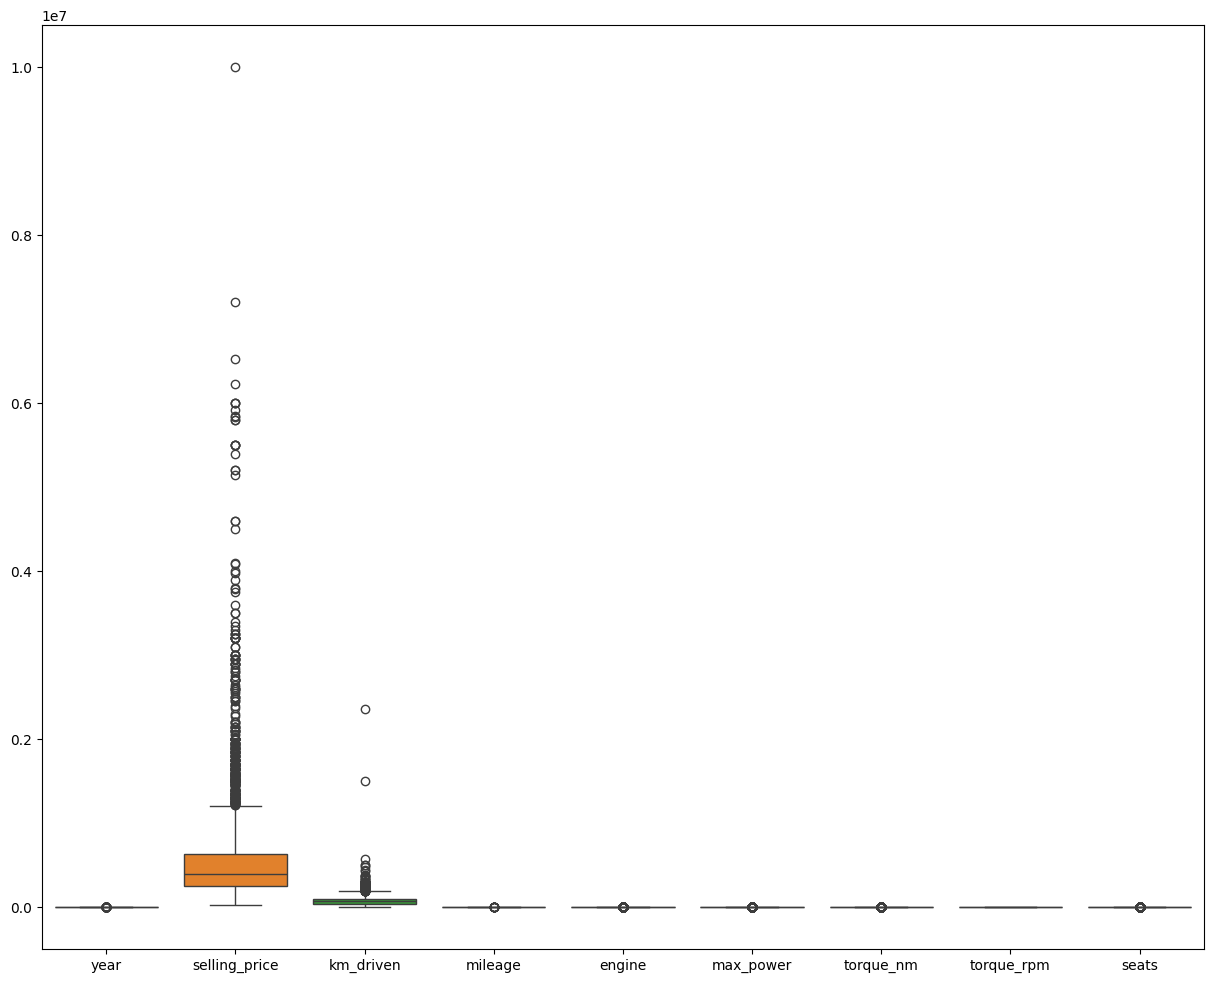

In [46]:
plt.figure(figsize=(15,12)) # boxplot-only numerical values, skips categorical values
sns.boxplot(data = df[['year', 'selling_price', 'km_driven','mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 'seats']])

In [47]:
# ---------- 1. Prepare: zeros in these columns are hidden nulls ----------
df[['mileage', 'max_power']] = df[['mileage', 'max_power']].replace(0, np.nan)

def detect_outliers(data):
    outliers = []
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    IQR = q3 - q1
    lb = q1 - (1.5 * IQR)
    ub = q3 + (1.5 * IQR)

    for i in data:
        if (i < lb or i > ub):
            outliers.append(i)

    return outliers

numerical_columns = ['year', 'selling_price', 'km_driven','mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 'seats']

for column in numerical_columns:
    outliers = detect_outliers(df[column])
    print(f"{column}: {len(outliers)} outliers")
    print("Values:", outliers)
    print("-" * 50)

year: 77 outliers
Values: [2001, 1999, 2000, 1983, 1999, 2000, 1999, 2000, 2000, 1996, 2001, 1994, 1999, 1994, 2000, 1995, 2000, 2001, 2000, 2001, 1998, 1999, 1997, 2001, 2000, 1998, 1999, 1999, 2000, 1995, 2001, 1998, 2001, 1996, 2000, 1999, 1998, 2001, 1998, 1999, 1994, 2000, 2000, 1999, 1991, 1999, 1997, 1997, 2000, 1998, 2000, 1997, 1997, 1997, 2001, 2000, 2000, 1997, 1998, 1999, 1998, 1999, 1999, 1997, 2000, 1999, 1999, 1996, 1997, 2000, 1998, 1999, 2000, 2000, 1998, 1997, 1997]
--------------------------------------------------
selling_price: 328 outliers
Values: [2100000, 1500000, 1450000, 1650000, 1750000, 1590000, 1689999, 1425000, 1700000, 2500000, 1700000, 3975000, 5150000, 3200000, 4100000, 4500000, 6000000, 3790000, 2150000, 5800000, 1864999, 2700000, 1750000, 3400000, 2650000, 5850000, 2625000, 2550000, 2700000, 1525000, 2150000, 1900000, 2900000, 10000000, 1750000, 1250000, 1380000, 1300000, 4600000, 1300000, 1250000, 1210000, 3000000, 1550000, 3800000, 2000000, 5400000,

In [48]:
df.nunique().sort_values()

transmission        2
seller_type         3
fuel                4
owner               5
seats               9
year               29
torque_rpm         57
engine            121
torque_nm         243
max_power         318
mileage           380
torque            441
selling_price     677
km_driven         921
name             2058
dtype: int64

In [49]:
# ---------- 1. Prepare: zeros in these columns are hidden nulls ----------
df[['mileage', 'max_power']] = df[['mileage', 'max_power']].replace(0, np.nan)

# ---------- 2. Outlier function (IQR rule) ----------
def detect_outliers(s):
    s = s.dropna()                         # nulls would otherwise break the bounds
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < lb) | (s > ub)], lb, ub

# continuous columns only (year and seats are discrete, so the IQR rule doesn't fit)
numerical_columns = ['year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
                       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque_nm',
                       'torque_rpm', 'seats']

# ---------- 3. Summary table: count first, then details ----------
summary = []
for col in numerical_columns:
    out, lb, ub = detect_outliers(df[col])
    summary.append({
        'column': col,
        'count': len(out),
        'pct': round(len(out) / len(df) * 100, 1),
        'lower_bound': round(lb, 2),
        'upper_bound': round(ub, 2),
        'min_outlier': out.min() if len(out) else None,
        'max_outlier': out.max() if len(out) else None,
    })

print(pd.DataFrame(summary).to_string(index=False))

# ---------- 4. Count, then values (unique values with how often they occur) ----------
for col in numerical_columns:
    out, lb, ub = detect_outliers(df[col])
    print("\n" + "-" * 50)
    print(f"{col}: {len(out)} outliers  (bounds: {lb:.2f} to {ub:.2f})")
    if len(out):
        print("Values (value: occurrences):")
        print(out.value_counts().sort_index().to_dict())

       column  count  pct  lower_bound  upper_bound  min_outlier  max_outlier
         year     77  1.1      2002.00       2026.0       1983.0       2001.0
selling_price    328  4.7   -325250.00    1208750.0    1210000.0   10000000.0
    km_driven    167  2.4    -50000.00     190000.0     191000.0    2360457.0
         fuel      0  0.0        -2.00          6.0          NaN          NaN
  seller_type    708 10.2         1.00          1.0          0.0          2.0
 transmission    584  8.4         1.00          1.0          0.0          0.0
        owner      0  0.0        -3.00          5.0          NaN          NaN
      mileage     12  0.2         9.02         30.3          9.0         42.0
       engine   1207 17.4       745.50       1949.5        624.0       3604.0
    max_power    371  5.4        21.50        145.5        147.5        400.0
    torque_nm    200  2.9       -52.50        351.5        355.0        789.0
   torque_rpm      0  0.0      -875.00       6125.0          NaN

In [47]:
# ---------- 5. Inspect the actual rows for a suspicious column ----------
out, lb, ub = detect_outliers(df['km_driven'])
print("\nTop 10 km_driven outliers:")
print(df.loc[out.index, ['name', 'year', 'km_driven', 'selling_price']]
        .sort_values('km_driven', ascending=False)
        .head(10))


Top 10 km_driven outliers:
                                               name  year  km_driven  \
3486                           Hyundai i20 Asta 1.2  2007    2360457   
1810                         Mahindra XUV500 W6 2WD  2012    1500000   
3508                       Maruti Wagon R LXI Minor  2010     577414   
3641                       Maruti Wagon R VXI BS IV  2011     500000   
6673  Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII  2011     500000   
5106                          Mahindra Scorpio M2DI  2011     475000   
5189         Toyota Innova 2.5 VX (Diesel) 7 Seater  2013     440000   
5467   Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV  2010     426000   
2272                            Mahindra Bolero SLE  2010     380000   
7102            Toyota Innova 2.5 V Diesel 8-seater  2007     376412   

      selling_price  
3486         550000  
1810         500000  
3508         194000  
3641         229999  
6673         350000  
5106         400000  
5189         750000  
546

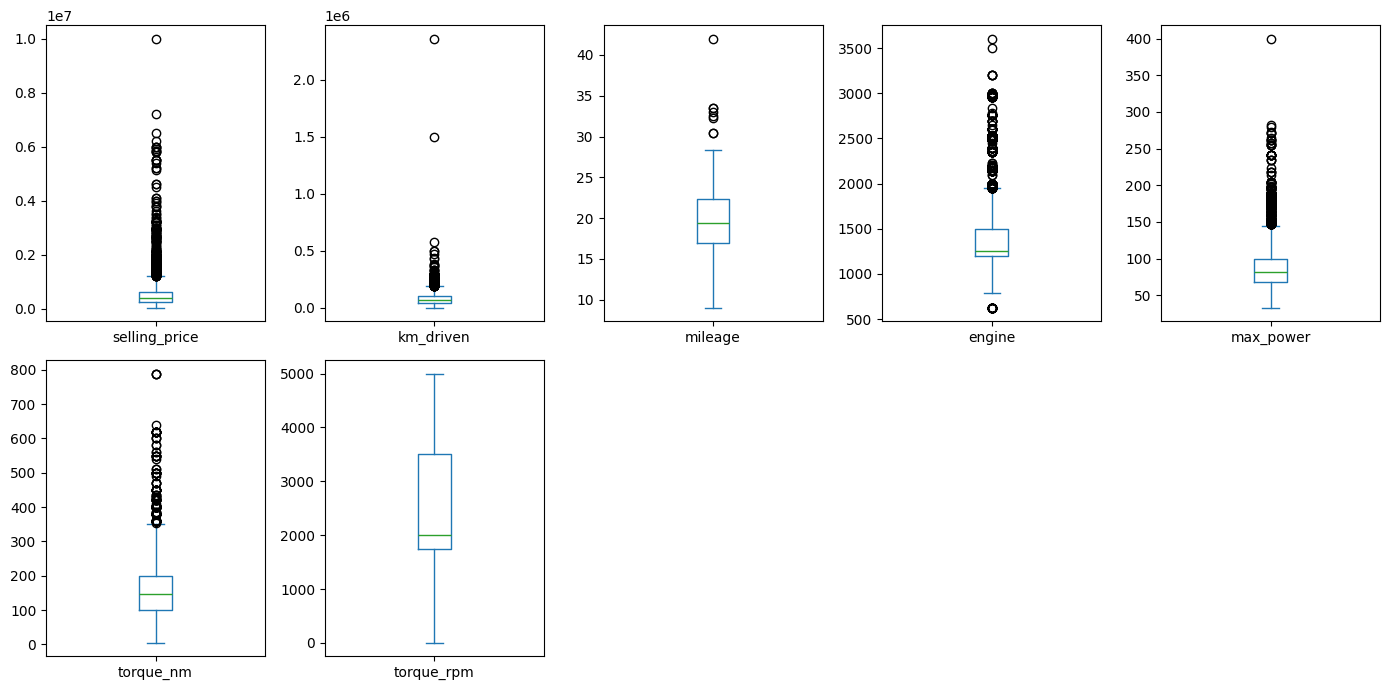

In [48]:
# ---------- 6. Box plots ----------
df[numerical_columns].plot(kind='box', subplots=True, layout=(2, 5), figsize=(14, 7))
plt.tight_layout()
plt.show()

In [24]:
def handle_outliers(data):

    tenth_percentile = np.percentile(data, 10)
    ninetieth_percentile = np.percentile(data, 90)

    b = np.where(data<tenth_percentile, tenth_percentile, data)

    b1 = np.where(b>ninetieth_percentile, ninetieth_percentile, b)
    return b1

for i in ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 'seats']:
    df[i]=handle_outliers(df[i])

In [49]:
def handle_outliers(s):
    s = s.copy()
    q1, q3 = s.quantile([0.25, 0.75])      # NaN is skipped automatically
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s.clip(lower=lb, upper=ub)      # NaN stays NaN

# continuous columns that need capping
for c in ['km_driven', 'mileage', 'engine', 'max_power', 'torque_nm']:
    df[c] = handle_outliers(df[c])

# price: transform instead of capping so expensive cars keep their rank
df['selling_price'] = np.log1p(df['selling_price'])

# year, seats, torque_rpm: leave unchanged

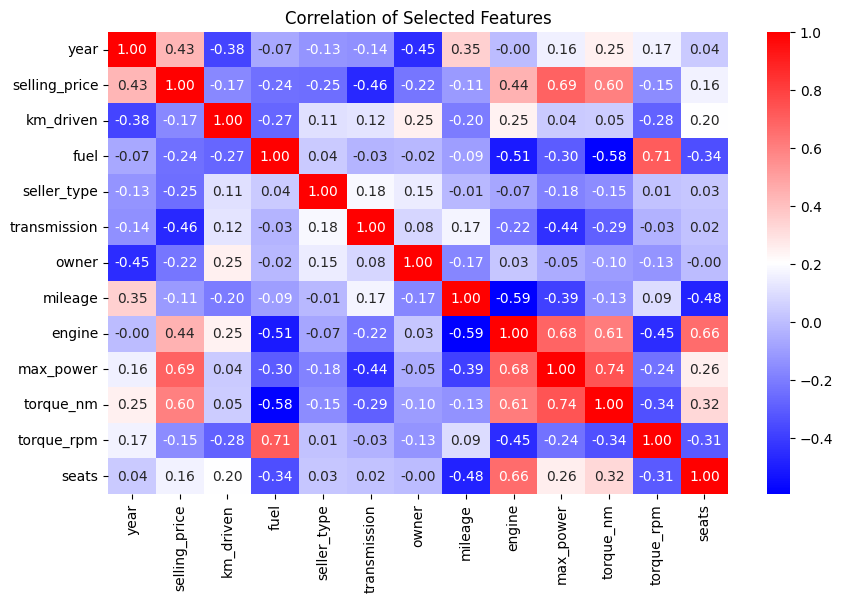

In [30]:
selected_cols = ['year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
                       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque_nm',
                       'torque_rpm', 'seats']

# Filter df and compute correlation
plt.figure(figsize=(10, 6))
sns.heatmap(df[selected_cols].corr(), annot=True, cmap='bwr', fmt='.2f')
plt.title("Correlation of Selected Features")
plt.show()

### Train test split

In [51]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm
0,Maruti Swift Dzire VDI,2014,13.017005,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,190.0,2000.0
1,Skoda Rapid 1.5 TDI Ambition,2014,12.821261,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,250.0,1500.0
2,Honda City 2017-2020 EXi,2006,11.970357,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,12.7,2.0
3,Hyundai i20 Sportz Diesel,2010,12.323860,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,22.4,1750.0
4,Maruti Swift VXI BSIII,2007,11.775297,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,11.5,4.0


In [52]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'torque_rpm']
Categorical: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'torque']


In [53]:
from sklearn.model_selection import train_test_split
# feature_cols = ['year', 'km_driven', 'fuel', 'seller_type',
#             'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm']
feature_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm',]

X = df[feature_cols]
y = df.selling_price

7


In [77]:
from sklearn.model_selection import train_test_split
# feature_cols = ['year', 'km_driven', 'fuel', 'seller_type',
#             'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm']
feature_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 
                'fuel', 'seller_type', 'transmission', 'owner', 'seats']

X = df[feature_cols]
y = df.selling_price

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=0)

In [80]:
from sklearn.model_selection import train_test_split

feature_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 
                'fuel', 'seller_type', 'transmission', 'owner', 'seats']

X = df[feature_cols]
y = df['selling_price']          # or np.log1p(df['selling_price'])
        
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [81]:
from sklearn.preprocessing import StandardScaler
num_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 
            'fuel', 'seller_type', 'transmission', 'owner', 'seats']
X_train, X_test = X_train.copy(), X_test.copy()
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [59]:
from sklearn.preprocessing import StandardScaler

scale = StandardScaler()
k = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque_nm', 'torque_rpm', 'seats']
df[k]=scale.fit_transform(df[k])

In [93]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from livelossplot import PlotLossesKerasTF
from sklearn.metrics import mean_absolute_error, r2_score

In [83]:
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

In [84]:
print(X_train.shape, X_test.shape)          # (rows, 8) for 8 features
print(X_train.isna().sum().sum())           # should be 0
print(X_train[num_cols].mean().round(2))    # about 0 if scaled

(5540, 12) (1386, 12)
0
year           -0.0
km_driven      -0.0
mileage         0.0
engine         -0.0
max_power       0.0
torque_nm      -0.0
torque_rpm     -0.0
fuel            0.0
seller_type     0.0
transmission    0.0
owner           0.0
seats          -0.0
dtype: float64


In [85]:
X_train, X_test

(          year  km_driven   mileage    engine  max_power  torque_nm  \
 5586  1.121745  -1.090822  0.901997  0.405160   0.491876   0.551047   
 3468 -0.830955   2.247468 -0.011997 -0.322200  -0.160607  -0.154875   
 4935 -0.586867   0.071824  0.901997  0.108397   0.150589  -1.633723   
 2485 -1.075042   1.510742 -0.047940 -0.322200  -0.462661   0.371575   
 4491 -2.539567   2.707922 -1.639727  0.390613  -0.154132   0.335681   
 ...        ...        ...       ...       ...        ...        ...   
 4286 -2.051392   0.405653 -1.460009 -0.173819  -0.611213  -1.773711   
 5986 -1.075042  -0.031778 -0.869508 -0.470582  -0.039862  -0.549713   
 6021 -0.342780  -0.371455 -0.227658 -0.470582  -0.009390  -0.537749   
 6268  1.365832  -1.331455  0.442433 -0.470582  -0.161750  -0.549713   
 914   1.121745  -0.054801  1.158736 -0.502586  -0.459995   0.374447   
 
       torque_rpm      fuel  seller_type  transmission     owner    seats  
 5586   -0.636989 -0.877061     0.311781      0.305531 -0.

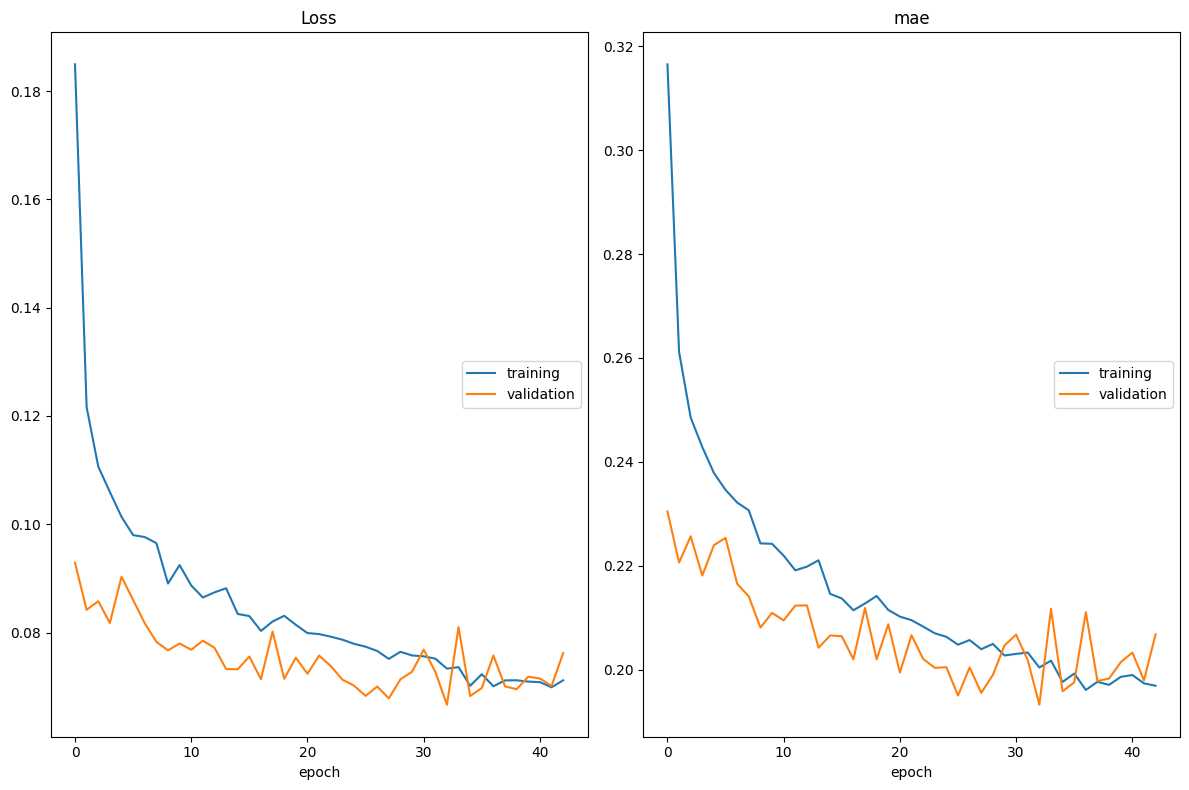

Loss
	training         	 (min:    0.070, max:    0.185, cur:    0.071)
	validation       	 (min:    0.067, max:    0.093, cur:    0.076)
mae
	training         	 (min:    0.196, max:    0.317, cur:    0.197)
	validation       	 (min:    0.193, max:    0.230, cur:    0.207)
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0712 - mae: 0.1969 - val_loss: 0.0762 - val_mae: 0.2068
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE: 0.2013197624484165  R2: 0.8681171996890797


In [94]:
# Perceptron
model=Sequential()

# Add input and hidden Layer
model.add(Input(shape=(X_train.shape[1],), name="Input_Layer"))

model.add(Dense(128, activation='relu', name="Hidden_1"))
model.add(Dropout(0.2))

model.add(Dense(64, activation='relu', name="Hidden_2"))
model.add(Dropout(0.2))

model.add(Dense(32, activation='relu', name="Hidden_3"))

model.add(Dense(16, activation='relu', name="Hidden_4"))

# output layer (linear for regression)
model.add(Dense(1, activation='linear', name="OutputLayer"))

# compile the model
opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(loss='mse', optimizer=opt, metrics=['mae'])

# train the model
y_mean = y_train.mean()

model.fit(X_train, y_train - y_mean,
          epochs=50, batch_size=32, validation_split=0.2,
          callbacks=[PlotLossesKerasTF(),
                     EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

pred = model.predict(X_test).flatten() + y_mean
print("MAE:", mean_absolute_error(y_test, pred), " R2:", r2_score(y_test, pred))

In [ ]:
# 1. smaller network
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='linear'))

model.compile(loss='mse', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), metrics=['mae'])

# 2. centre the target: train on (y - mean), then add the mean back
y_mean = y_train.mean()

model.fit(X_train, y_train - y_mean,
          epochs=100, batch_size=32, validation_split=0.2,
          callbacks=[PlotLossesKerasTF(),
                     EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

pred = model.predict(X_test).flatten() + y_mean
print("MAE:", mean_absolute_error(y_test, pred), " R2:", r2_score(y_test, pred))

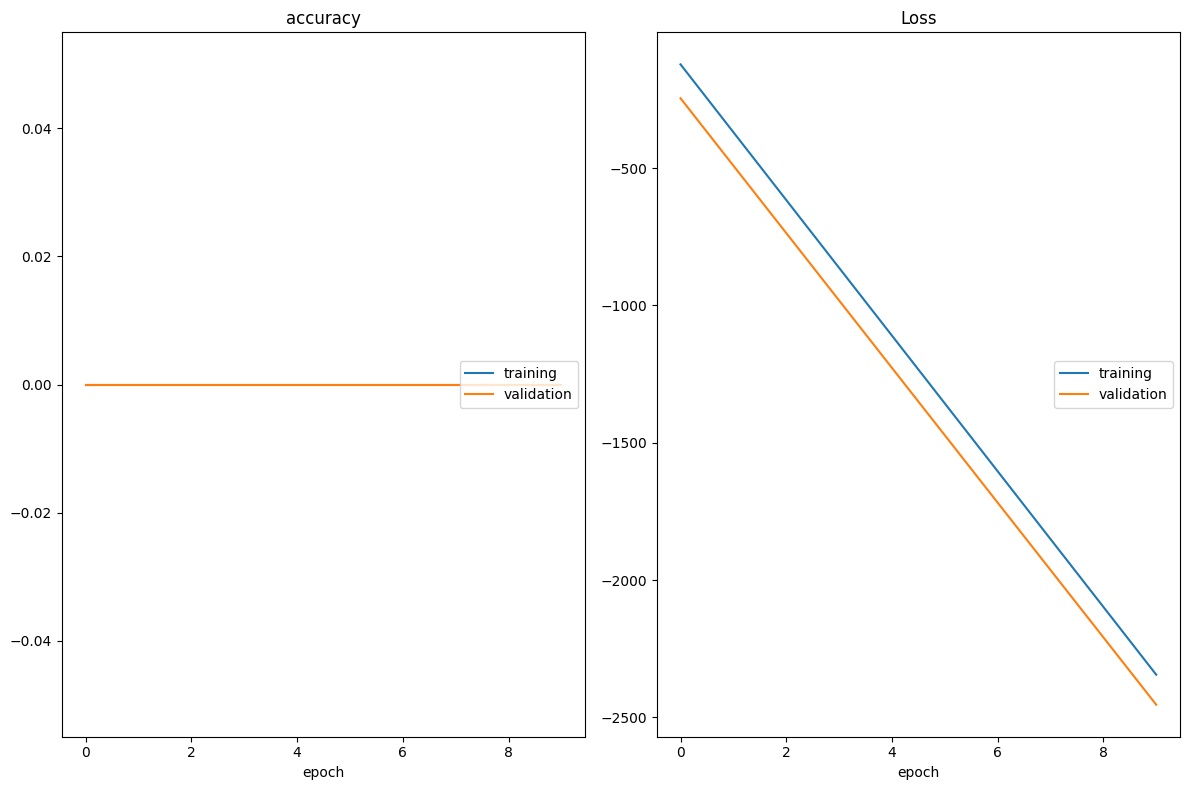

accuracy
	training         	 (min:    0.000, max:    0.000, cur:    0.000)
	validation       	 (min:    0.000, max:    0.000, cur:    0.000)
Loss
	training         	 (min: -2344.463, max: -122.630, cur: -2344.463)
	validation       	 (min: -2453.722, max: -246.025, cur: -2453.722)
174/174 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.0000e+00 - loss: -2344.4631 - val_accuracy: 0.0000e+00 - val_loss: -2453.7217


In [75]:
#SGD
model=Sequential()
model.add(Input(shape=(8,),name="Input Layer"))

model.add(Dense(1,activation='sigmoid',name='OutputLayer'))

opt = tf.keras.optimizers.SGD(learning_rate=0.01)
model.compile(loss='binary_crossentropy',optimizer=opt,metrics=['accuracy'])

model.fit(X_train,y_train,epochs=10,validation_data=(X_test,y_test),callbacks=[PlotLossesKerasTF()])

In [95]:
from sklearn.metrics import classification_report

In [96]:
t= model.predict(X_test)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [97]:
t

array([[ 0.14354761],
       [ 0.83964825],
       [ 0.6246876 ],
       ...,
       [-0.40983346],
       [ 0.4662164 ],
       [ 0.65822273]], dtype=float32)

In [98]:
print(len(t))

1386


In [102]:
pred = model.predict(X_test).flatten() + y_mean      # y_mean from the centred-target version

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2  :", r2_score(y_test, pred))
print("MAE (Rs):", mean_absolute_error(np.expm1(y_test), np.expm1(pred)))

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
MAE : 0.2013197624484165
RMSE: 0.27141210858898934
R2  : 0.8681171996890797
MAE (Rs): 98748.10347898632


In [99]:
t1 = []
for i in range(len(t)):
    if t[i] >= 0.5:
        t1.append(1)
    else:
        t1.append(0)

In [100]:
new_pred = pd.Series(t1)  
print(new_pred)

0       0
1       1
2       1
3       0
4       1
       ..
1381    0
1382    0
1383    0
1384    0
1385    1
Length: 1386, dtype: int64


In [103]:
print(classification_report(y_test,pred))

ValueError: continuous is not supported

In [32]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

features = [
    'year',
    'km_driven',
    'mileage',
    'engine',
    'max_power',
    'torque_nm',
    'torque_rpm',
    'seats'
]

X_vif = df[features].replace(
    [np.inf, -np.inf], np.nan
).dropna()

vif_data = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [
        variance_inflation_factor(
            X_vif.values, i
        )
        for i in range(X_vif.shape[1])
    ]
})

print(vif_data.sort_values(
    'VIF', ascending=False
))

      Feature         VIF
0        year  204.011854
7       seats   69.552848
2     mileage   53.913598
3      engine   46.430238
4   max_power   30.627501
5   torque_nm   11.983750
6  torque_rpm    7.751889
1   km_driven    3.009423
